# 02 · Backpropagation

A 2-layer network (input → hidden → output) trained on **XOR**, with every gradient derived and coded by hand. Numpy only.

**Forward pass**

$$Z_1 = XW_1 + b_1,\quad A_1 = \sigma(Z_1),\quad Z_2 = A_1W_2 + b_2,\quad A_2 = \sigma(Z_2)$$

**Loss** — binary cross-entropy, averaged over the batch of $m$ samples:

$$L = -\frac1m\sum\big[y\log A_2 + (1-y)\log(1-A_2)\big]$$

**Backward pass** — the chain rule, from the output backwards. With sigmoid + cross-entropy the output gradient simplifies neatly:

$$dZ_2 = \frac{A_2 - y}{m},\quad dW_2 = A_1^{T}dZ_2,\quad db_2 = \textstyle\sum dZ_2$$
$$dA_1 = dZ_2\,W_2^{T},\quad dZ_1 = dA_1\odot A_1(1-A_1),\quad dW_1 = X^{T}dZ_1,\quad db_1 = \textstyle\sum dZ_1$$

**Update** (gradient descent): $W \leftarrow W - \alpha\,dW$.

Key idea: each layer reuses values cached in the forward pass, so the gradient of every parameter costs about one extra forward pass in total.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## The network

In [2]:
class NeuralNetwork:
    """Input -> Hidden (sigmoid) -> Output (sigmoid), binary cross-entropy loss."""

    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.1):
        self.lr = learning_rate
        # He-style scaling keeps early activations from shrinking/exploding
        self.W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2.0 / hidden_size)
        self.b2 = np.zeros((1, output_size))

    @staticmethod
    def sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def forward(self, X):
        self.X = X
        self.A1 = self.sigmoid(X @ self.W1 + self.b1)
        self.A2 = self.sigmoid(self.A1 @ self.W2 + self.b2)
        return self.A2

    def loss(self, y_pred, y_true):
        eps = 1e-15
        y_pred = np.clip(y_pred, eps, 1 - eps)
        return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

    def backward(self, y_true):
        m = y_true.shape[0]
        dZ2 = (self.A2 - y_true) / m             # sigmoid + BCE simplification, 1/m folded in
        dW2 = self.A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)
        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * self.A1 * (1 - self.A1)      # sigmoid'(z) = a(1-a)
        dW1 = self.X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def step(self, grads):
        for name, g in grads.items():
            setattr(self, name, getattr(self, name) - self.lr * g)

    def train_step(self, X, y):
        y_pred = self.forward(X)
        loss = self.loss(y_pred, y)
        self.step(self.backward(y))
        return loss

## Check the gradients numerically

Before trusting the training result, verify the hand-derived backward pass against finite differences:

$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta+\varepsilon) - L(\theta-\varepsilon)}{2\varepsilon}$$

If we got the calculus wrong, this disagrees. (A wrong gradient can still "kind of train", which makes this the most useful test you can write.)

In [3]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

net = NeuralNetwork(2, 4, 1)
net.forward(X)
grads = net.backward(y)

def loss_now():
    return net.loss(net.forward(X), y)

eps, worst = 1e-6, 0.0
for name, g in grads.items():
    p = getattr(net, name)
    for idx in np.ndindex(p.shape):
        orig = p[idx]
        p[idx] = orig + eps; lp = loss_now()
        p[idx] = orig - eps; lm = loss_now()
        p[idx] = orig
        num = (lp - lm) / (2 * eps)
        worst = max(worst, abs(num - g[idx]) / (abs(num) + abs(g[idx]) + 1e-12))
print(f"worst relative error over all {sum(g.size for g in grads.values())} parameters: {worst:.2e}")
assert worst < 1e-6, "backward pass disagrees with finite differences"

worst relative error over all 17 parameters: 1.12e-08


## Train on XOR

XOR is not linearly separable (see notebook 01), so the hidden layer must learn a useful intermediate representation. Try changing `hidden_size`, `lr` or `epochs` and re-running.

In [4]:
hidden_size, lr, epochs = 4, 0.5, 10_000

np.random.seed(42)
net = NeuralNetwork(2, hidden_size, 1, learning_rate=lr)

loss_history, acc_history = [], []
for epoch in range(epochs):
    loss_history.append(net.train_step(X, y))
    acc_history.append(np.mean((net.forward(X) >= 0.5) == y))
    if epoch % 2000 == 0:
        print(f"epoch {epoch:>5}  loss {loss_history[-1]:.4f}  acc {acc_history[-1]:.0%}")

final = net.forward(X)
print(f"\nfinal loss {net.loss(final, y):.6f}")
for xi, pi, ti in zip(X, final, y):
    print(f"  {xi.astype(int)} -> {pi[0]:.4f} ({int(pi[0] >= 0.5)})   target {int(ti[0])}")

assert np.all((final >= 0.5) == y), "network failed to learn XOR"

epoch     0  loss 0.7304  acc 50%


epoch  2000  loss 0.0173  acc 100%


epoch  4000  loss 0.0059  acc 100%


epoch  6000  loss 0.0035  acc 100%


epoch  8000  loss 0.0025  acc 100%



final loss 0.001926
  [0 0] -> 0.0003 (0)   target 0
  [0 1] -> 0.9979 (1)   target 1
  [1 0] -> 0.9981 (1)   target 1
  [1 1] -> 0.0035 (0)   target 0


## Training curves and what the network learned

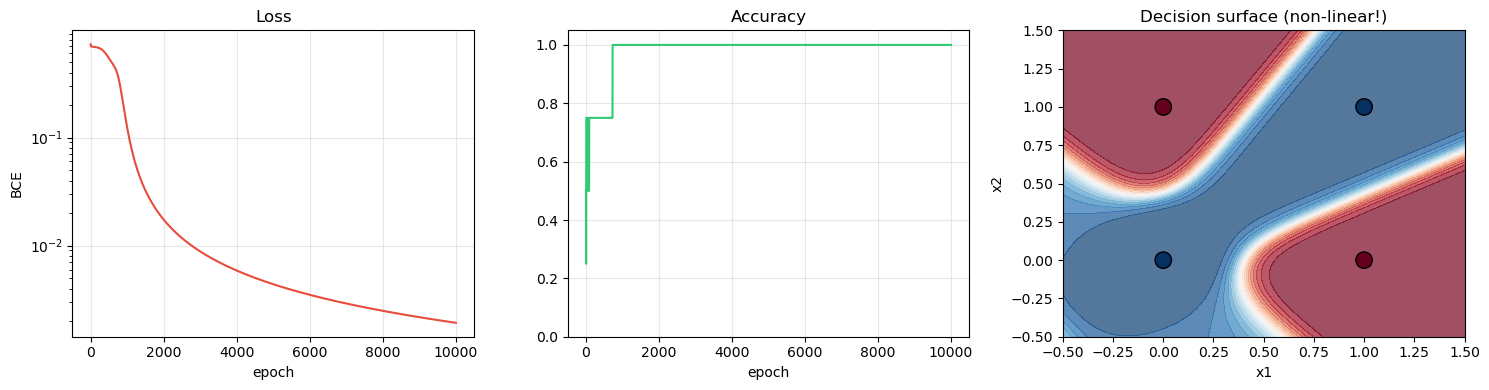

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(loss_history, color="#e74c3c")
axes[0].set(title="Loss", xlabel="epoch", ylabel="BCE", yscale="log")
axes[0].grid(alpha=0.3)

axes[1].plot(acc_history, color="#2ecc71")
axes[1].set(title="Accuracy", xlabel="epoch", ylim=(0, 1.05))
axes[1].grid(alpha=0.3)

xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
Z = net.forward(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[2].contourf(xx, yy, Z, levels=20, cmap="RdBu_r", alpha=0.7, vmin=0, vmax=1)
axes[2].scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap="RdBu_r", s=140, edgecolor="k")
axes[2].set(title="Decision surface (non-linear!)", xlabel="x1", ylabel="x2")

plt.tight_layout()
plt.show()

The decision surface wraps around the two 1-corners with a curved region — something no single line (notebook 01) can do. That is the hidden layer's contribution.

**Next: `03_optimizers`** — plain gradient descent works here, but momentum, RMSprop and Adam converge faster and more robustly on harder problems.